In [2]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


umap_result形状: (42, 3)
数据框形状: (42, 5)

每个聚类的细胞数量：
Cluster 0: 27 cells
Cluster 1: 15 cells


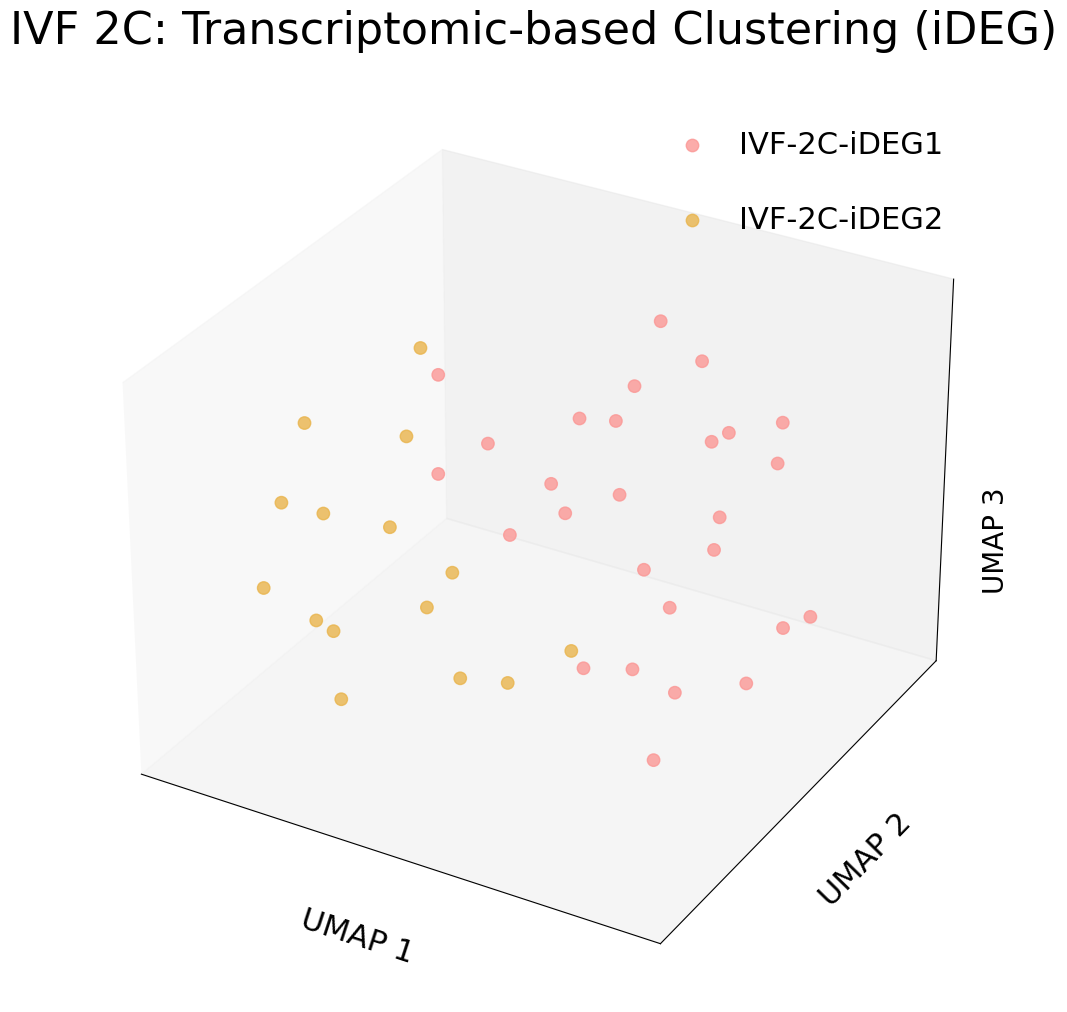

In [4]:
#scRNAseq IVF 2C
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

# 设置绘图字体
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置随机种子
seed = 99
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("/home/lihaoxing/jupyter/IVF_2C_all_log2TPM_dip.txt", sep="\t", index_col=0).transpose()

# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# PCA 降维
sc.tl.pca(adata, random_state=seed)

# 构建邻接图
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 执行UMAP降维至3D
sc.tl.umap(adata, n_components=3, random_state=seed)
umap_result = adata.obsm['X_umap']
print("umap_result形状:", umap_result.shape)

# Leiden 聚类
sc.tl.leiden(adata, flavor="igraph", resolution=0.82, random_state=seed)
clusters = adata.obs["leiden"]

# 构建聚类 + UMAP 数据框
clusters_df = pd.DataFrame(list(clusters.items()), columns=["cell_id", "cluster_id"])
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])
combined_df = pd.concat([clusters_df, umap_df], axis=1)
print("数据框形状:", combined_df.shape)

# 保存聚类和UMAP坐标信息
with open('IVF_2C_dip_seed99.txt', 'w') as file:
    for index, row in combined_df.iterrows():
        line = '\t'.join([str(value) for value in row.values])
        file.write(line + '\n')

# 计算聚类大小并排序（从大到小）
cluster_sizes = combined_df["cluster_id"].value_counts()
sorted_cluster_ids = cluster_sizes.sort_values(ascending=False).index.tolist()

# 根据细胞数量分配颜色
color_map = {cluster_id: '#fb9795' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#E9B44C' 
             for cluster_id in cluster_sizes.index}

# 计算聚类大小并排序（从大到小）
cluster_sizes = combined_df["cluster_id"].value_counts()
sorted_cluster_ids = cluster_sizes.sort_values(ascending=False).index.tolist()

# 打印每个聚类的细胞数量
print("\n每个聚类的细胞数量：")
for cluster_id, count in cluster_sizes.items():
    print(f"Cluster {cluster_id}: {count} cells")

    
# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# =========================
# 三维绘图
# =========================
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index

    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"IVF-2C-iDEG{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.8,
        s=80,   # 点更大
        c=color_map[cluster_id]
    )

# =========================
# 标题 & 坐标轴
# =========================
ax.set_title("IVF 2C: Transcriptomic-based Clustering (iDEG)", pad=25)

ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# =========================
# 保存（高清）
# =========================
plt.savefig(
    'IVF_2C_Transcriptomic-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()


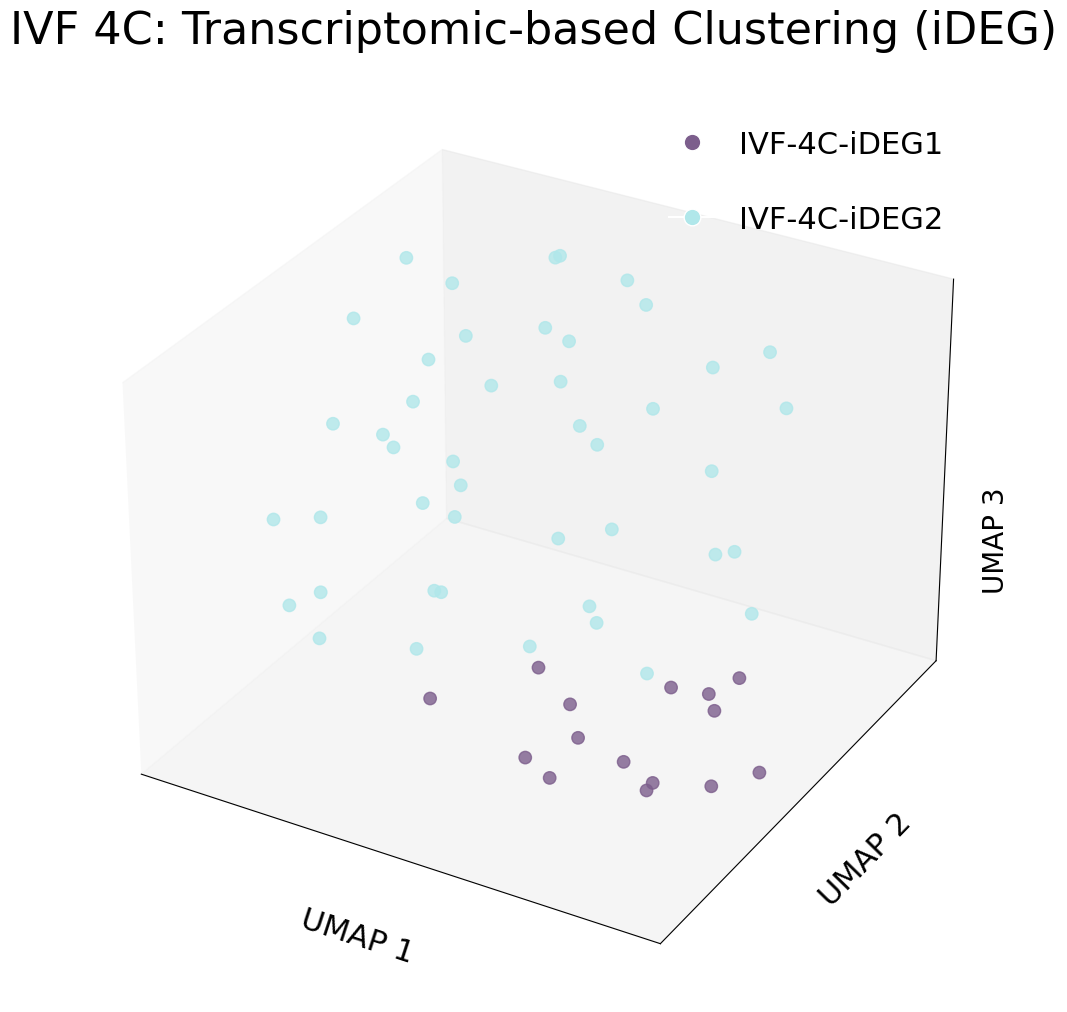

In [5]:
# =========================
# scRNAseq IVF 4C
# =========================
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.lines import Line2D

# =========================
# 全局设置
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 22,
    "axes.titlesize": 32,
    "axes.labelsize": 22,
    "legend.fontsize": 22,
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

seed = 99
np.random.seed(seed)

# =========================
# 读取数据
# =========================
expression_matrix = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_4C_all_log2TPM_dip.txt",
    sep="\t",
    index_col=0
).transpose()

adata = sc.AnnData(expression_matrix)

# =========================
# 降维 + 聚类
# =========================
sc.tl.pca(adata, random_state=seed)
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

sc.tl.umap(adata, n_components=3, random_state=seed)
umap_result = adata.obsm['X_umap']

sc.tl.leiden(adata, flavor="igraph", resolution=0.45, random_state=seed)
clusters = adata.obs["leiden"]

# =========================
# 整理数据
# =========================
clusters_df = pd.DataFrame(list(clusters.items()), columns=["cell_id", "cluster_id"])
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 保存结果
combined_df.to_csv("IVF_4C_dip_seed99.txt", sep="\t", index=False)

# =========================
# cluster信息
# =========================
cluster_sizes = combined_df["cluster_id"].value_counts()
sorted_cluster_ids = cluster_sizes.sort_values(ascending=False).index.tolist()

# 分类规则
def get_group(cluster_id):
    return "iDEG1" if cluster_sizes[cluster_id] < cluster_sizes.mean() else "iDEG2"

# 颜色
color_dict = {
    "iDEG1": "#7c5e8c",
    "iDEG2": "#b0e7ea"
}

# =========================
# 3D 绘图
# =========================
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in sorted_cluster_ids:
    idx = combined_df["cluster_id"] == cluster_id
    group = get_group(cluster_id)

    ax.scatter(
        combined_df.loc[idx, "UMAP_1"],
        combined_df.loc[idx, "UMAP_2"],
        combined_df.loc[idx, "UMAP_3"],
        alpha=0.8,
        s=80,
        c=color_dict[group]
    )

# =========================
# 标题 & 坐标轴
# =========================
ax.set_title("IVF 4C: Transcriptomic-based Clustering (iDEG)", pad=25)

ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("")

# 替代Z轴标签（防裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 手动 legend（关键！顺序固定）
# =========================
legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           label='IVF-4C-iDEG1',
           markerfacecolor=color_dict["iDEG1"], markersize=12),
    Line2D([0], [0], marker='o', color='w',
           label='IVF-4C-iDEG2',
           markerfacecolor=color_dict["iDEG2"], markersize=12)
]

ax.legend(
    handles=legend_elements,
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# =========================
# 保存
# =========================
plt.savefig(
    'IVF_4C_Transcriptomic-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

2026-06-25 10:55:30.908915: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-25 10:55:46.385588: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


umap_result形状: (24, 3)
clusters_df形状: (24, 2)
数据框形状: (24, 5)


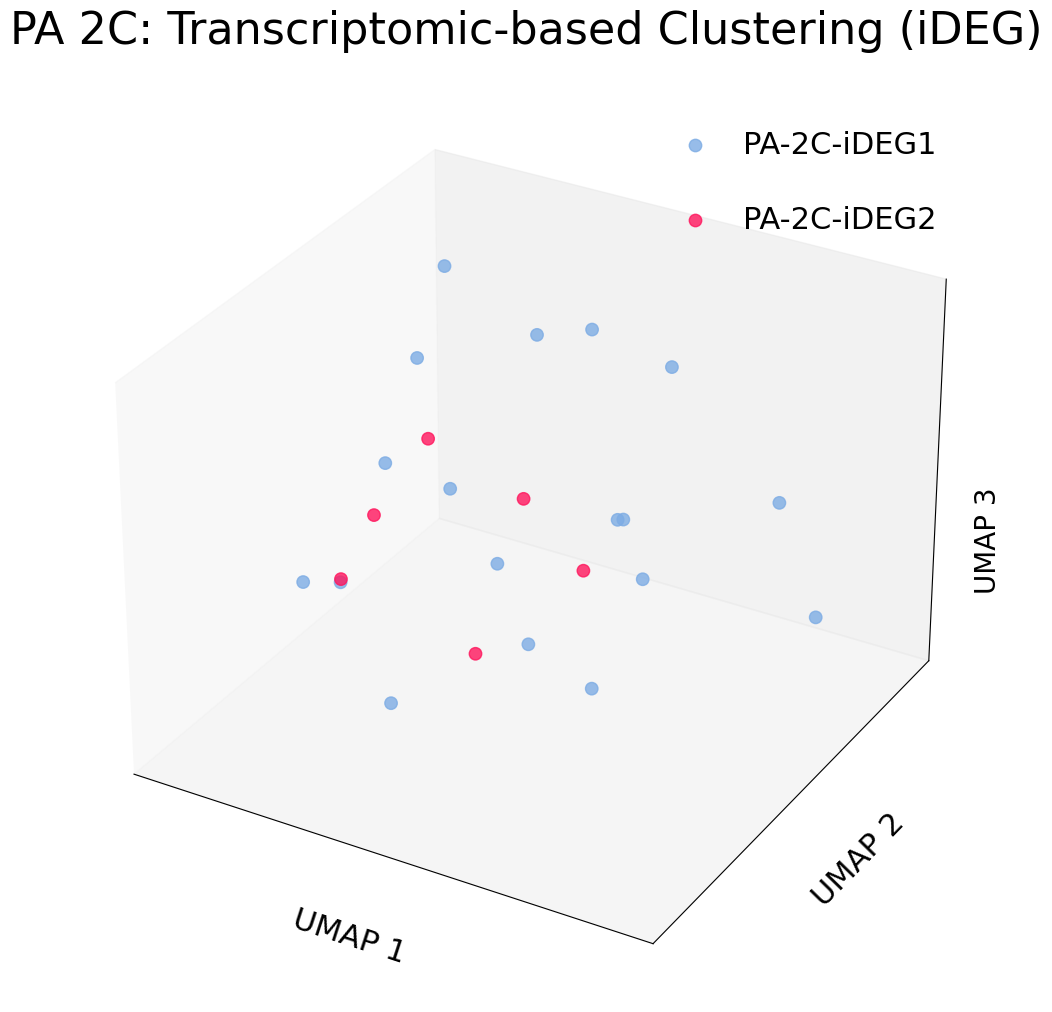

In [1]:
#scRNAseq PA 2c 2024年12月19日 dip seed 0 10 20 30 60 99

import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置随机种子
seed = 99
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("/home/lihaoxing/jupyter/PA_2C_all_log2TPM_dip.txt", sep="\t", index_col=0).transpose()
# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# 主成分分析（PCA），并可视化 PCA 的方差比例
sc.tl.pca(adata, random_state=seed)

# 使用 PCA 结果计算细胞之间的近邻关系，使用原始数据进行邻域计算
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 使用 UMAP 算法对数据进行降维
sc.tl.umap(adata, n_components=3, random_state=seed)
# 获取UMAP结果
umap_result = adata.obsm['X_umap']

# 打印UMAP结果的形状
print("umap_result形状:", umap_result.shape)

# 使用 Leiden 算法进行细胞聚类,通过调整resolution大小调整聚类数量多少
sc.tl.leiden(adata, flavor="igraph", resolution=0.55, random_state=seed)

# 获取聚类结果
clusters = adata.obs["leiden"]

# 构建包含细胞 ID 和对应聚类 ID 的列表
data = [(cell_id, cluster_id) for cell_id, cluster_id in clusters.items()]

# 转换为数据框
clusters_df = pd.DataFrame(data, columns=["cell_id", "cluster_id"])
print("clusters_df形状:", clusters_df.shape)

# 将UMAP结果转换为数据框，并设置列名为 'UMAP_1', 'UMAP_2' 和 'UMAP_3'
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])

# 将聚类结果和UMAP结果左右拼接为一个新的数据框
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 打印新数据框的形状
print("数据框形状:", combined_df.shape)
#print(combined_df)

with open('PA_2C_dip_seed99.txt', 'w') as file:
    # 遍历DataFrame的每一行
    for index, row in combined_df.iterrows():
        # 将每行内容转换为字符串
        line = '\t'.join([str(value) for value in row.values])
        # 写入文件
        file.write(line + '\n')
        
# 计算每个聚类的细胞数量
cluster_sizes = combined_df["cluster_id"].value_counts()

# 根据细胞数量分配颜色，细胞多的用红色，少的用蓝色
color_map = {cluster_id: '#7dace4' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#ff165d' 
             for cluster_id in cluster_sizes.index}

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# =========================
# 三维绘图
# =========================
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index

    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"PA-2C-iDEG{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.8,
        s=80,   # 点更大
        c=color_map[cluster_id]
    )

# =========================
# 标题 & 坐标轴
# =========================
ax.set_title("PA 2C: Transcriptomic-based Clustering (iDEG)", pad=25)

ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# =========================
# 保存（高清）
# =========================
plt.savefig(
    'PA_2C_Transcriptomic-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()




umap_result形状: (39, 3)
clusters_df形状: (39, 2)
数据框形状: (39, 5)


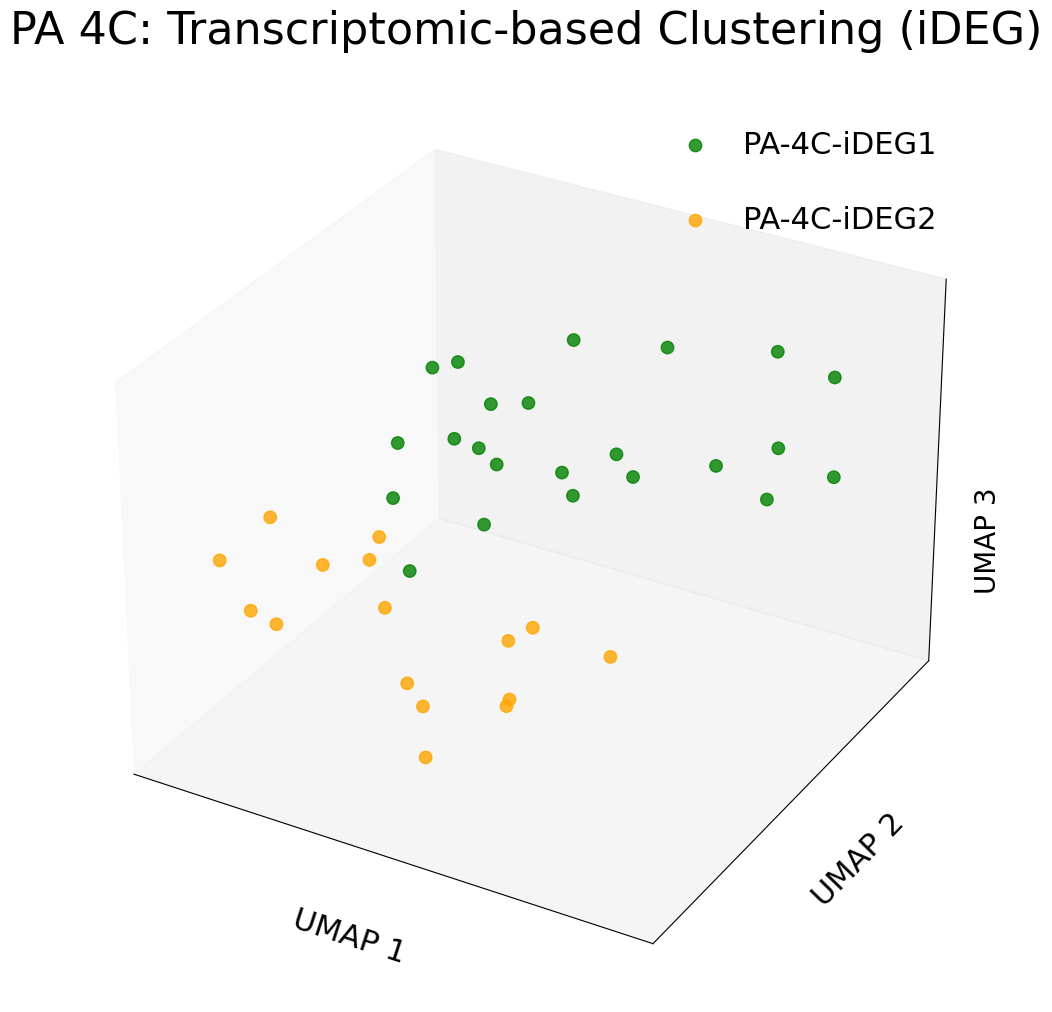

In [2]:
#scRNAseq PA 4c 2024年12月19日 dip seed 0 10 20 30 60 99

import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置随机种子
seed = 99
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("/home/lihaoxing/jupyter/PA_4C_all_log2TPM_dip.txt", sep="\t", index_col=0).transpose()
# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# 主成分分析（PCA），并可视化 PCA 的方差比例
sc.tl.pca(adata, random_state=seed)

# 使用 PCA 结果计算细胞之间的近邻关系，使用原始数据进行邻域计算
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 使用 UMAP 算法对数据进行降维
sc.tl.umap(adata, n_components=3, random_state=seed)
# 获取UMAP结果
umap_result = adata.obsm['X_umap']

# 打印UMAP结果的形状
print("umap_result形状:", umap_result.shape)

# 使用 Leiden 算法进行细胞聚类,通过调整resolution大小调整聚类数量多少
sc.tl.leiden(adata, flavor="igraph", resolution=0.55, random_state=seed)

# 获取聚类结果
clusters = adata.obs["leiden"]

# 构建包含细胞 ID 和对应聚类 ID 的列表
data = [(cell_id, cluster_id) for cell_id, cluster_id in clusters.items()]

# 转换为数据框
clusters_df = pd.DataFrame(data, columns=["cell_id", "cluster_id"])
print("clusters_df形状:", clusters_df.shape)

# 将UMAP结果转换为数据框，并设置列名为 'UMAP_1', 'UMAP_2' 和 'UMAP_3'
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])

# 将聚类结果和UMAP结果左右拼接为一个新的数据框
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 打印新数据框的形状
print("数据框形状:", combined_df.shape)
#print(combined_df)

with open('PA_4C_dip_seed99.txt', 'w') as file:
    # 遍历DataFrame的每一行
    for index, row in combined_df.iterrows():
        # 将每行内容转换为字符串
        line = '\t'.join([str(value) for value in row.values])
        # 写入文件
        file.write(line + '\n')
        
# 计算每个聚类的细胞数量
cluster_sizes = combined_df["cluster_id"].value_counts()

# 根据细胞数量分配颜色，细胞多的用红色，少的用蓝色
color_map = {cluster_id: 'green' if cluster_sizes[cluster_id] > cluster_sizes.mean() else 'orange' 
             for cluster_id in cluster_sizes.index}

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# =========================
# 三维绘图
# =========================
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index

    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"PA-4C-iDEG{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.8,
        s=80,   # 点更大
        c=color_map[cluster_id]
    )

# =========================
# 标题 & 坐标轴
# =========================
ax.set_title("PA 4C: Transcriptomic-based Clustering (iDEG)", pad=25)

ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# =========================
# 保存（高清）
# =========================
plt.savefig(
    'PA_4C_Transcriptomic-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()




In [6]:
cd /home/lihaoxing/scRNAseq/Telescope/dip

/home/lihaoxing/scRNAseq/Telescope/dip


umap_result形状: (42, 3)
数据框形状: (42, 5)

每个聚类的细胞数量：
Cluster 0: 26 cells
Cluster 1: 16 cells


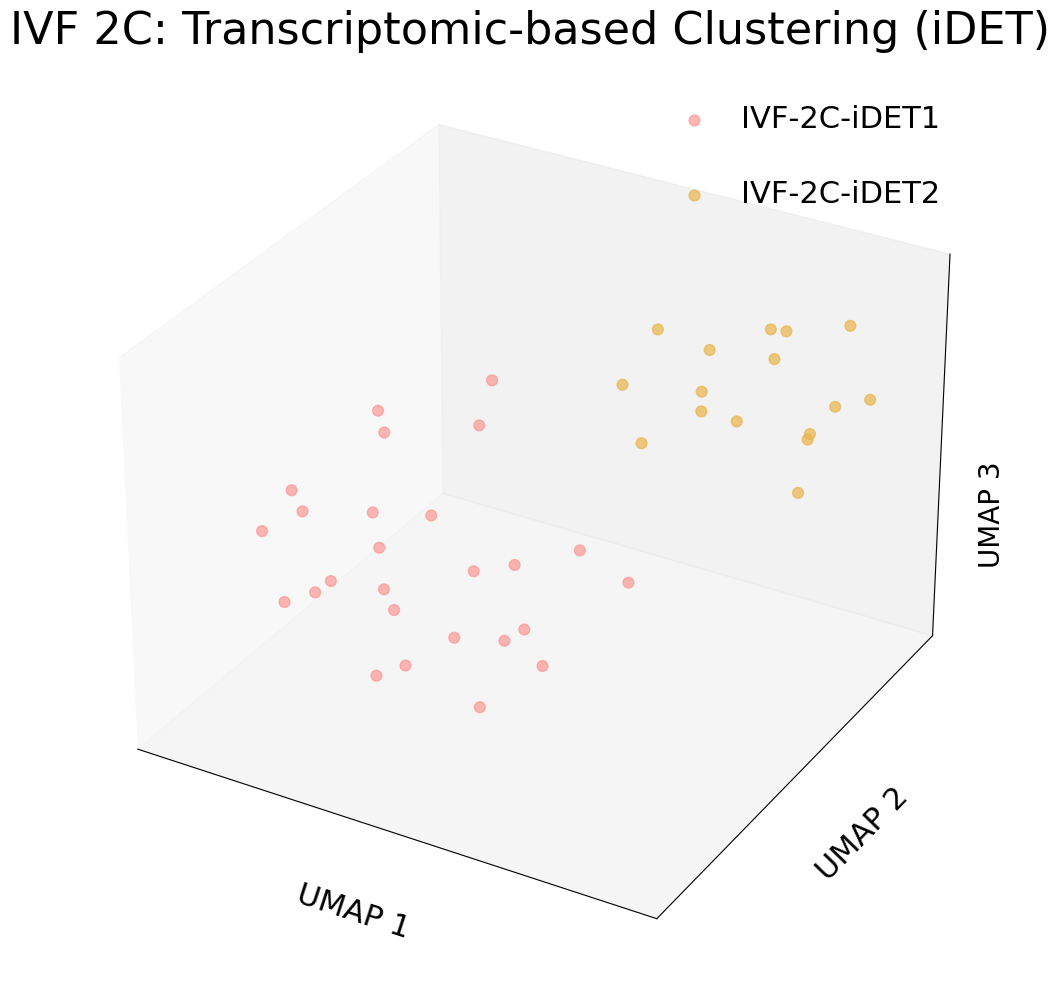

In [7]:
#scRNAseq IVF 2C dipTE
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

# 设置绘图字体
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# 设置随机种子
seed = 99
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("IVF_R2C_TE_dip_TE_transcript_matrix.txt", sep="\t", index_col=0).transpose()

# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# PCA 降维
sc.tl.pca(adata, random_state=seed)

# 构建邻接图
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 执行UMAP降维至3D
sc.tl.umap(adata, n_components=3, random_state=seed)
umap_result = adata.obsm['X_umap']
print("umap_result形状:", umap_result.shape)

# Leiden 聚类
sc.tl.leiden(adata, flavor="igraph", resolution=0.4, random_state=seed)
clusters = adata.obs["leiden"]

# 构建聚类 + UMAP 数据框
clusters_df = pd.DataFrame(list(clusters.items()), columns=["cell_id", "cluster_id"])
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])
combined_df = pd.concat([clusters_df, umap_df], axis=1)
print("数据框形状:", combined_df.shape)

# 保存聚类和UMAP坐标信息
with open('IVF_2C_iDET-copy_seed99.txt', 'w') as file:
    for index, row in combined_df.iterrows():
        line = '\t'.join([str(value) for value in row.values])
        file.write(line + '\n')

# 计算聚类大小并排序（从大到小）
cluster_sizes = combined_df["cluster_id"].value_counts()
sorted_cluster_ids = cluster_sizes.sort_values(ascending=False).index.tolist()

# 根据细胞数量分配颜色
color_map = {cluster_id: '#fb9795' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#E9B44C' 
             for cluster_id in cluster_sizes.index}



# 计算聚类大小并排序（从大到小）
cluster_sizes = combined_df["cluster_id"].value_counts()
sorted_cluster_ids = cluster_sizes.sort_values(ascending=False).index.tolist()

# 打印每个聚类的细胞数量
print("\n每个聚类的细胞数量：")
for cluster_id, count in cluster_sizes.items():
    print(f"Cluster {cluster_id}: {count} cells")

    
# 绘制三维UMAP聚类图
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in sorted_cluster_ids:
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index
    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"IVF-2C-iDET{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.7,
        s=60,
        c=color_map[cluster_id]
    )

# 图形美化设置
ax.set_title("IVF 2C: Transcriptomic-based Clustering (iDET)")
# 设置坐标轴标题，但不显示刻度
ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='upper right',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)
# 保存图片为 PDF

# 保存图像
plt.savefig('IVF_2C_iDET-copy_Clustering.svg', dpi=300, bbox_inches='tight', transparent=True)


umap_result形状: (60, 3)
数据框形状: (60, 5)


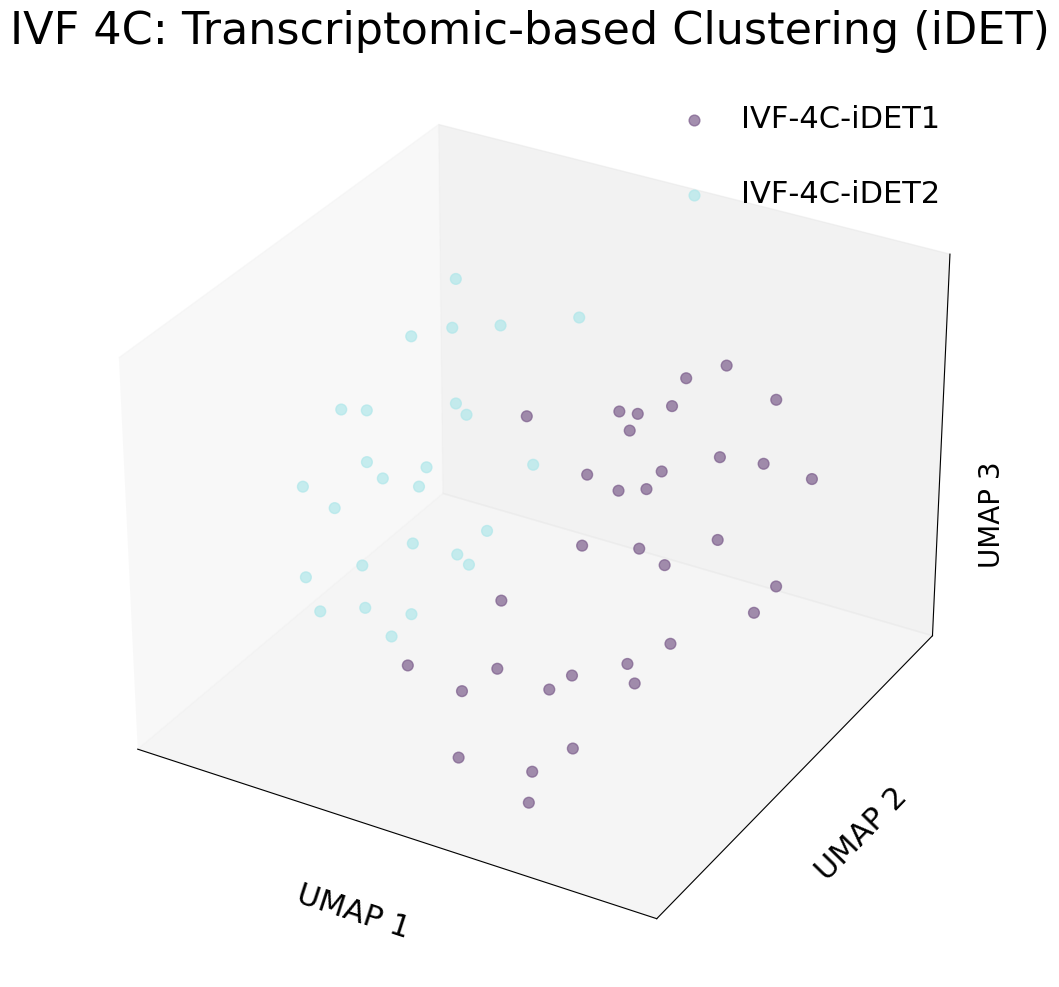

In [8]:
#scRNAseq IVF 4C dipTE
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

# 设置绘图字体
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# 设置随机种子
seed = 80
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("IVF_R4C_TE_dip_TE_transcript_matrix.txt", sep="\t", index_col=0).transpose()

# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# PCA 降维
sc.tl.pca(adata, random_state=seed)

# 构建邻接图
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 执行UMAP降维至3D
sc.tl.umap(adata, n_components=3, random_state=seed)
umap_result = adata.obsm['X_umap']
print("umap_result形状:", umap_result.shape)

# Leiden 聚类
sc.tl.leiden(adata, flavor="igraph", resolution=0.5, random_state=seed)
clusters = adata.obs["leiden"]

# 构建聚类 + UMAP 数据框
clusters_df = pd.DataFrame(list(clusters.items()), columns=["cell_id", "cluster_id"])
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])
combined_df = pd.concat([clusters_df, umap_df], axis=1)
print("数据框形状:", combined_df.shape)

# 保存聚类和UMAP坐标信息
with open('IVF_4C_iDET-copy_seed99.txt', 'w') as file:
    for index, row in combined_df.iterrows():
        line = '\t'.join([str(value) for value in row.values])
        file.write(line + '\n')

# 计算聚类大小并排序（从大到小）
cluster_sizes = combined_df["cluster_id"].value_counts()
sorted_cluster_ids = cluster_sizes.sort_values(ascending=False).index.tolist()

# 根据细胞数量分配颜色
color_map = {cluster_id: '#7c5e8c' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#b0e7ea' 
             for cluster_id in cluster_sizes.index}


# 绘制三维UMAP聚类图
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in sorted_cluster_ids:
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index
    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"IVF-4C-iDET{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.7,
        s=60,
        c=color_map[cluster_id]
    )

# 图形美化设置
ax.set_title("IVF 4C: Transcriptomic-based Clustering (iDET)")
# 设置坐标轴标题，但不显示刻度
ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='upper right',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)
# 保存图片为 PDF

# 保存图像
plt.savefig('IVF_4C_iDET-copy_Clustering.svg', dpi=300, bbox_inches='tight', transparent=True)


umap_result形状: (24, 3)
clusters_df形状: (24, 2)
数据框形状: (24, 5)


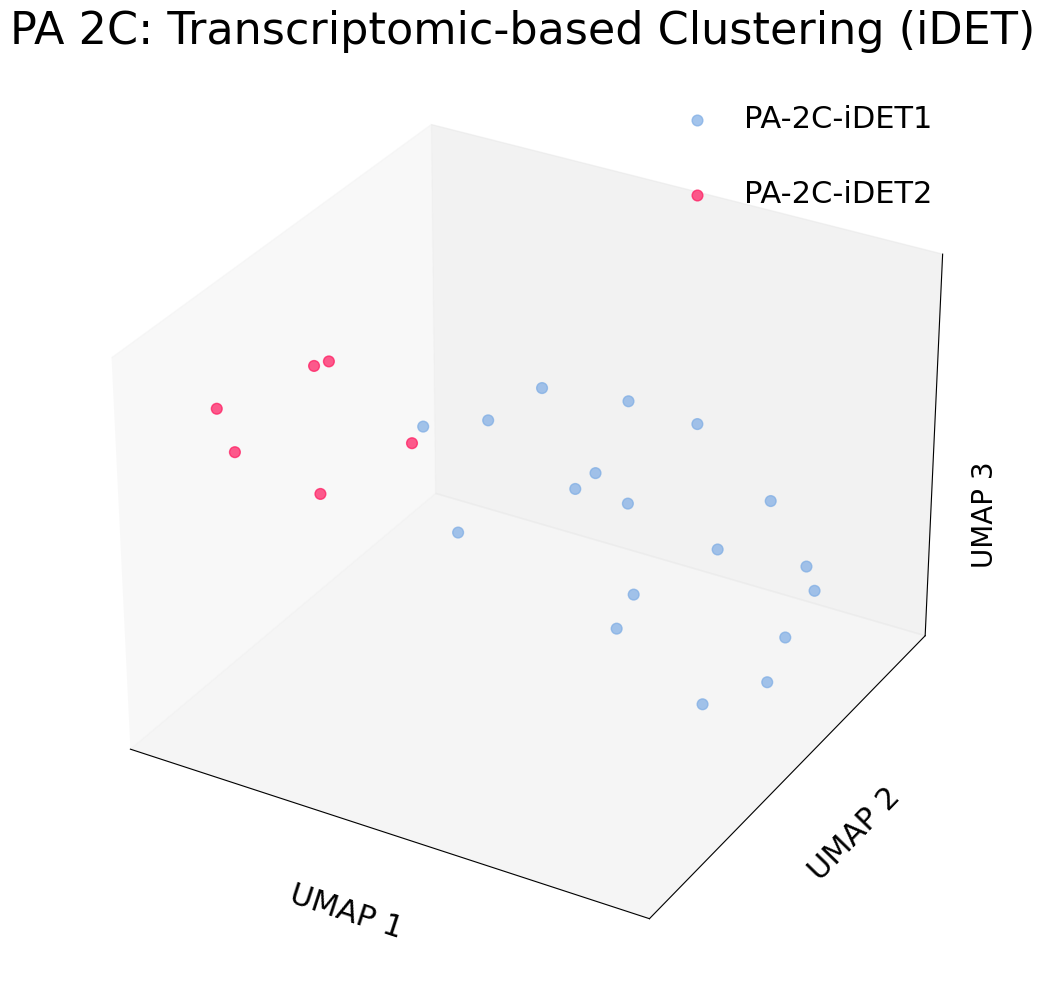

In [7]:
#scRNAseq PA 2c 2026年1月29日 dipTE seed 0 10 20 30 60 99

import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# 设置随机种子
seed = 99
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("PA_R2C_TE_dip_TE_transcript_matrix.txt", sep="\t", index_col=0).transpose()
# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# 主成分分析（PCA），并可视化 PCA 的方差比例
sc.tl.pca(adata, random_state=seed)

# 使用 PCA 结果计算细胞之间的近邻关系，使用原始数据进行邻域计算
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 使用 UMAP 算法对数据进行降维
sc.tl.umap(adata, n_components=3, random_state=seed)
# 获取UMAP结果
umap_result = adata.obsm['X_umap']

# 打印UMAP结果的形状
print("umap_result形状:", umap_result.shape)

# 使用 Leiden 算法进行细胞聚类,通过调整resolution大小调整聚类数量多少
sc.tl.leiden(adata, flavor="igraph", resolution=0.3, random_state=seed)

# 获取聚类结果
clusters = adata.obs["leiden"]

# 构建包含细胞 ID 和对应聚类 ID 的列表
data = [(cell_id, cluster_id) for cell_id, cluster_id in clusters.items()]

# 转换为数据框
clusters_df = pd.DataFrame(data, columns=["cell_id", "cluster_id"])
print("clusters_df形状:", clusters_df.shape)

# 将UMAP结果转换为数据框，并设置列名为 'UMAP_1', 'UMAP_2' 和 'UMAP_3'
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])

# 将聚类结果和UMAP结果左右拼接为一个新的数据框
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 打印新数据框的形状
print("数据框形状:", combined_df.shape)
#print(combined_df)

with open('PA_2C_iDET-copy_seed99.txt', 'w') as file:
    # 遍历DataFrame的每一行
    for index, row in combined_df.iterrows():
        # 将每行内容转换为字符串
        line = '\t'.join([str(value) for value in row.values])
        # 写入文件
        file.write(line + '\n')
        
# 计算每个聚类的细胞数量
cluster_sizes = combined_df["cluster_id"].value_counts()

# 根据细胞数量分配颜色，细胞多的用红色，少的用蓝色
color_map = {cluster_id: '#7dace4' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#ff165d' 
             for cluster_id in cluster_sizes.index}

# 三维绘图
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

# 绘制每个聚类的散点图，颜色根据聚类的细胞数量
for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index
    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"PA-2C-iDET{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.7,  # 调整散点透明度
        s=60,  # 调整散点大小
        c=color_map[cluster_id]  # 设置颜色
    )

ax.set_title("PA 2C: Transcriptomic-based Clustering (iDET)")  # 调整标题字体大小
# 设置坐标轴标题，但不显示刻度
ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)
# 保存图片为 PDF
plt.savefig('PA_2C_iDET-copy_Clustering.svg', dpi=300, bbox_inches='tight', transparent=True)



umap_result形状: (39, 3)
clusters_df形状: (39, 2)
数据框形状: (39, 5)


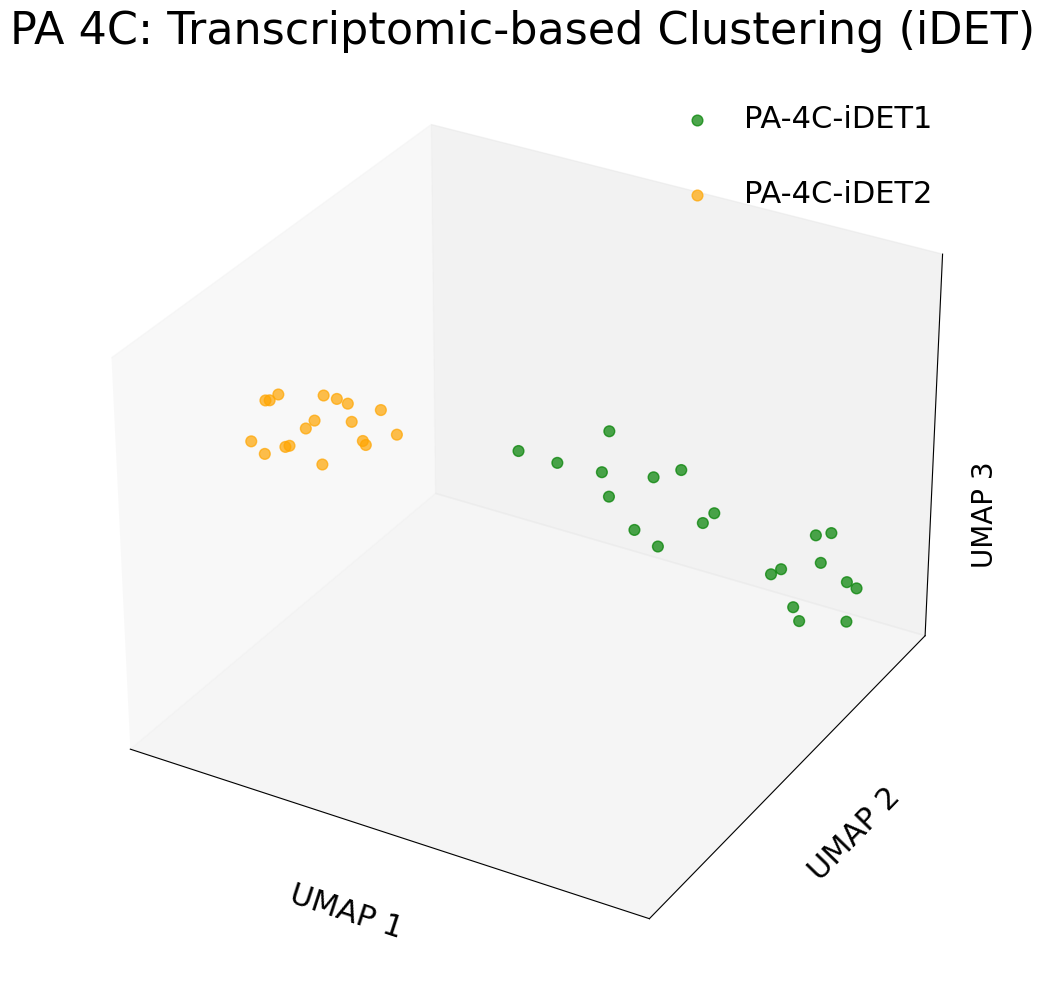

In [8]:
#scRNAseq PA 4c dipTE

import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# 设置随机种子
seed = 10
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("PA_R4C_TE_dip_TE_transcript_matrix.txt", sep="\t", index_col=0).transpose()
# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# 主成分分析（PCA），并可视化 PCA 的方差比例
sc.tl.pca(adata, random_state=seed)

# 使用 PCA 结果计算细胞之间的近邻关系，使用原始数据进行邻域计算
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 使用 UMAP 算法对数据进行降维
sc.tl.umap(adata, n_components=3, random_state=seed)
# 获取UMAP结果
umap_result = adata.obsm['X_umap']

# 打印UMAP结果的形状
print("umap_result形状:", umap_result.shape)

# 使用 Leiden 算法进行细胞聚类,通过调整resolution大小调整聚类数量多少
sc.tl.leiden(adata, flavor="igraph", resolution=0.4, random_state=seed)

# 获取聚类结果
clusters = adata.obs["leiden"]

# 构建包含细胞 ID 和对应聚类 ID 的列表
data = [(cell_id, cluster_id) for cell_id, cluster_id in clusters.items()]

# 转换为数据框
clusters_df = pd.DataFrame(data, columns=["cell_id", "cluster_id"])
print("clusters_df形状:", clusters_df.shape)

# 将UMAP结果转换为数据框，并设置列名为 'UMAP_1', 'UMAP_2' 和 'UMAP_3'
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])

# 将聚类结果和UMAP结果左右拼接为一个新的数据框
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 打印新数据框的形状
print("数据框形状:", combined_df.shape)
#print(combined_df)

with open('PA_4C_iDET-copy_seed99.txt', 'w') as file:
    # 遍历DataFrame的每一行
    for index, row in combined_df.iterrows():
        # 将每行内容转换为字符串
        line = '\t'.join([str(value) for value in row.values])
        # 写入文件
        file.write(line + '\n')
        
# 计算每个聚类的细胞数量
cluster_sizes = combined_df["cluster_id"].value_counts()

# 根据细胞数量分配颜色，细胞多的用红色，少的用蓝色
color_map = {cluster_id: 'green' if cluster_sizes[cluster_id] > cluster_sizes.mean() else 'orange' 
             for cluster_id in cluster_sizes.index}

# 三维绘图
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

# 绘制每个聚类的散点图，颜色根据聚类的细胞数量
for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index
    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"PA-4C-iDET{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.7,  # 调整散点透明度
        s=60,  # 调整散点大小
        c=color_map[cluster_id]  # 设置颜色
    )

ax.set_title("PA 4C: Transcriptomic-based Clustering (iDET)")  # 调整标题字体大小
# 设置坐标轴标题，但不显示刻度
ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)
# 保存图片为 PDF
# 保存图片为 PDF
plt.savefig('PA_4C_iDET-copy_Clustering.svg', dpi=300, bbox_inches='tight', transparent=True)

